# Del bloque al próximo token

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

| | |
|---|---|
| **Problema** | La atención le entrega a cada token un vector, pero un modelo de lenguaje tiene que terminar en otra cosa: un puntaje para cada uno de los 50.257 tokens que podrían venir después. |
| **Producto** | El primer bloque de GPT-2 recalculado pieza por pieza y comprobado contra el modelo, la distribución real del próximo token y una tabla de aciertos y errores sobre el verso. |
| **Recursos** | GPT-2 en español (`DeepESP/gpt2-spanish`, unos 250 MB, descargado antes de la clase según `ANTES_DE_LA_CLASE.md`). Corre en CPU en pocos segundos. |

En el cuaderno 02 abrimos una cabeza de atención. Pero GPT-2 no devuelve vectores de contexto: devuelve, para cada token de su vocabulario, qué tan probable es que venga después. Entre una cosa y la otra hay piezas del mapa que todavía no abrimos: doce cabezas juntas, sumas, normalizaciones y una red.

**¿Cómo se convierte lo que calcula la atención en una distribución de probabilidad sobre el próximo token, y qué parte de lo que «sabe» el modelo está en el mecanismo y qué parte en los pesos?**

> **Cómo se trabaja.** Recalculás el primer bloque de GPT-2 sobre el verso del *Martín Fierro*, pieza por pieza, y cada pieza se compara con la del modelo. Al final de las secciones 4 y 6 hay un **microlaboratorio**: una tabla te dice qué líneas completar y con qué, y la celda siguiente comprueba si quedó bien.

In [1]:
import numpy as np
import torch
import transformers
from transformers import GPT2LMHeadModel

import utils

# Muestra los numeros con dos decimales y sin notacion cientifica.
np.set_printoptions(precision=2, suppress=True)

version_de_numpy = np.__version__
version_de_torch = torch.__version__
version_de_transformers = transformers.__version__
print(f"numpy {version_de_numpy}, torch {version_de_torch}, "
      f"transformers {version_de_transformers}")

numpy 2.5.4, torch 2.14.1+cpu, transformers 4.57.6


El modelo es GPT-2 en español (`DeepESP/gpt2-spanish`, licencia MIT; entrenado con 11,5 GB de Wikipedia y libros en español, sin filtrar, según su ficha). El verso es el comienzo de *El gaucho Martín Fierro* (José Hernández, 1872, dominio público), cortado en 12 tokens como en los cuadernos 01 y 02.

In [2]:
tokenizador, modelo = utils.cargar_gpt2()

verso = "Aquí me pongo a cantar al compás de la vigüela"
codificado = tokenizador(verso, return_tensors="pt")
ids_del_verso = codificado["input_ids"]

tokens = []
rotulos = []
for numero in ids_del_verso[0]:
    token = tokenizador.decode(numero)
    tokens.append(token)
    rotulos.append(token.strip())

cantidad_de_tokens = len(tokens)
posicion_de_cantar = 4
print(f"{cantidad_de_tokens} tokens: {tokens}")

12 tokens: ['Aquí', ' me', ' pongo', ' a', ' cantar', ' al', ' compás', ' de', ' la', ' vig', 'ü', 'ela']


Le pedimos al modelo todos sus estados intermedios (`output_hidden_states=True`): la entrada de cada bloque y la salida final. Son la referencia contra la que vamos a comparar cada cuenta.

In [3]:
with torch.no_grad():
    salida_del_modelo = modelo(ids_del_verso, output_hidden_states=True)

# Un estado por bloque, mas la entrada: 13 en total. El [0] es el texto.
estados_del_modelo = []
for estado in salida_del_modelo.hidden_states:
    estados_del_modelo.append(estado[0].numpy())

entrada_del_bloque = estados_del_modelo[0]
print(f"Estados: {len(estados_del_modelo)}, cada uno de "
      f"{entrada_del_bloque.shape}")

Estados: 13, cada uno de (12, 768)


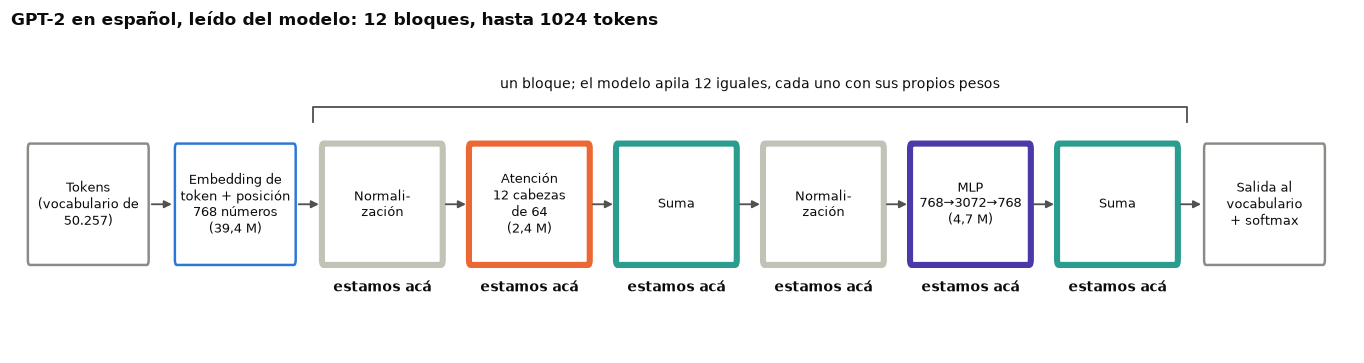

In [4]:
utils.dibujar_mapa_del_modelo(modelo, estamos_aca="bloques")

> **Para mirar.** En el cuaderno 02 abrimos la caja naranja. Ahora recorremos el bloque completo, de la primera normalización a la última suma, y después los 12 bloques hasta la salida.

## 1. Doce cabezas, un solo vector

En el cuaderno 02 calculamos una cabeza. El bloque calcula las 12 a la vez, cada una con sus 64 columnas de consulta, clave y valor. Encapsulamos en una función el procedimiento del cuaderno 02, con las mismas cuentas.

`utils.normalizar_como_gpt2` hace la normalización que abrimos en la sección 3; por ahora, alcanza con saber que va antes de la atención.

In [5]:
primer_bloque = modelo.transformer.h[0]

tapado = np.zeros((cantidad_de_tokens, cantidad_de_tokens), dtype=bool)
for fila in range(cantidad_de_tokens):
    for columna in range(cantidad_de_tokens):
        if columna > fila:
            tapado[fila, columna] = True


def atender_con_una_cabeza(
    proyecciones: np.ndarray, cabeza: int,
) -> np.ndarray:
    """Calcula lo que una cabeza de atencion le entrega a cada token.

    Args:
        proyecciones: Consultas, claves y valores de todas las cabezas
            juntos, una fila por token (2304 numeros por fila).
        cabeza: Numero de cabeza, de 0 a 11.

    Returns:
        Un vector de 64 numeros por token.
    """
    inicio = cabeza * 64
    consultas = proyecciones[:, inicio:inicio + 64]
    claves = proyecciones[:, 768 + inicio:768 + inicio + 64]
    valores = proyecciones[:, 1536 + inicio:1536 + inicio + 64]
    puntajes = consultas @ claves.T / 8
    puntajes[tapado] = -np.inf
    pesos = utils.softmax(puntajes)
    return pesos @ valores

In [6]:
primera_normalizacion = primer_bloque.ln_1
normalizada = utils.normalizar_como_gpt2(entrada_del_bloque,
                                         primera_normalizacion)
pesos_qkv = primer_bloque.attn.c_attn.weight.detach().numpy()
sesgos_qkv = primer_bloque.attn.c_attn.bias.detach().numpy()
proyecciones = normalizada @ pesos_qkv + sesgos_qkv

lo_que_da_cada_cabeza = []
for cabeza in range(12):
    lo_que_da_cada_cabeza.append(atender_con_una_cabeza(proyecciones, cabeza))

# axis=1 pega los resultados lado a lado: 12 cabezas por 64 numeros.
cabezas_unidas = np.concatenate(lo_que_da_cada_cabeza, axis=1)
print(f"Las 12 cabezas unidas: {cabezas_unidas.shape}")

Las 12 cabezas unidas: (12, 768)


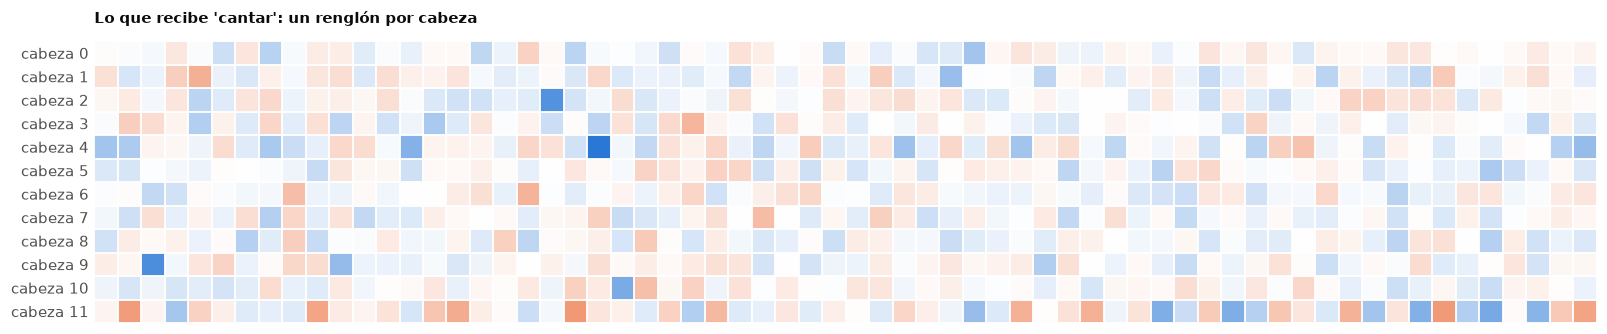

In [7]:
nombres_de_cabezas = []
for cabeza in range(12):
    nombres_de_cabezas.append(f"cabeza {cabeza}")

utils.dibujar_paneles(paneles=[{
    "matriz": cabezas_unidas[posicion_de_cantar].reshape(12, 64),
    "tipo": "vector", "filas": nombres_de_cabezas,
    "titulo": "Lo que recibe 'cantar': un rengl\u00f3n por cabeza",
}])

Después, una matriz de 768 × 768 **mezcla** los resultados de las 12 cabezas: cada número final puede combinar lo que encontró cualquiera de ellas. Comparamos el resultado con la atención que calcula el modelo.

In [8]:
pesos_de_mezcla = primer_bloque.attn.c_proj.weight.detach().numpy()
sesgos_de_mezcla = primer_bloque.attn.c_proj.bias.detach().numpy()
salida_de_la_atencion = cabezas_unidas @ pesos_de_mezcla + sesgos_de_mezcla

with torch.no_grad():
    primer_estado = salida_del_modelo.hidden_states[0]
    normalizada_del_modelo = primer_bloque.ln_1(primer_estado)
    atencion_del_modelo = primer_bloque.attn(normalizada_del_modelo)[0]
referencia = atencion_del_modelo[0].numpy()

diferencia = np.abs(salida_de_la_atencion - referencia).max()
print(f"Mayor diferencia con la atencion del modelo: {diferencia:.1e}")

Mayor diferencia con la atencion del modelo: 1.2e-07


> **Para mirar.** Cada renglón del dibujo es lo que aportó una cabeza a «cantar»; algunos renglones casi no tienen color. La cuenta coincide con la del modelo: salvo redondeo, las 12 cabezas más la mezcla **son** la atención del bloque.

## 2. Sumar: no perder lo que el token traía

La atención no reemplaza el vector del token: **se le suma**. Es la **conexión residual**: el token conserva lo que traía y le agrega lo que tomó de los demás.

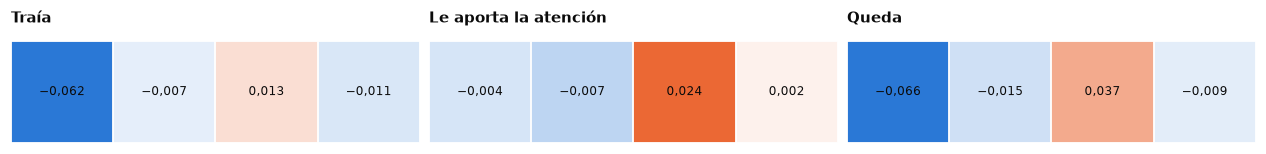

In [9]:
despues_de_sumar = entrada_del_bloque + salida_de_la_atencion

utils.dibujar_paneles(paneles=[
    {"matriz": entrada_del_bloque[posicion_de_cantar, 0:4], "tipo": "vector",
     "numeros": True, "decimales": 3, "titulo": "Tra\u00eda"},
    {"matriz": salida_de_la_atencion[posicion_de_cantar, 0:4],
     "tipo": "vector", "numeros": True, "decimales": 3,
     "titulo": "Le aporta la atenci\u00f3n"},
    {"matriz": despues_de_sumar[posicion_de_cantar, 0:4], "tipo": "vector",
     "numeros": True, "decimales": 3, "titulo": "Queda"},
])

Las cuatro primeras coordenadas de «cantar», sumadas lugar por lugar:

* −0,062 + (−0,004) = −0,066
* −0,007 + (−0,007) = −0,014 (con más decimales, −0,015)
* 0,013 + 0,024 = 0,037
* −0,011 + 0,002 = −0,009

> **Para mirar.** La suma deja reconocible lo que el token traía. Sin ella, cada bloque reescribiría el vector desde cero, y después de 12 bloques quedaría poco del token original.

## 3. Normalizar: mantener los números en escala

Antes de la red, el bloque **normaliza** cada vector: le resta su media y lo divide por su desvío, para que quede con media 0 y desvío 1. Después lo multiplica por una **ganancia** y le suma un **sesgo**, dos vectores de 768 números que también se aprendieron.

Con «cantar»: la media de sus 768 números es 0,0003 y el desvío, 0,0409. Para la primera coordenada:

* restar la media y dividir por el desvío: (−0,066 − 0,0003) / 0,0409 = −1,62
* multiplicar por la ganancia (0,81) y sumar el sesgo (0,06): −1,62 × 0,81 + 0,06 = −1,24

Con $\mu$ para la media y $\sigma$ para el desvío: $(x - \mu) / \sigma$, multiplicado por la ganancia, más el sesgo. El código suma un número muy chico al desvío (`eps`) para no dividir nunca por cero.

In [10]:
fila_de_cantar = despues_de_sumar[posicion_de_cantar]
segunda_normalizacion = primer_bloque.ln_2
ganancia = segunda_normalizacion.weight.detach().numpy()
sesgo = segunda_normalizacion.bias.detach().numpy()

media = fila_de_cantar.mean()
desvio = np.sqrt(fila_de_cantar.var() + segunda_normalizacion.eps)
centrada = (fila_de_cantar - media) / desvio
normalizada_de_cantar = centrada * ganancia + sesgo

print(f"Media {media:.4f}, desvio {desvio:.4f}")
print(f"Antes, de {fila_de_cantar.min():.2f} a {fila_de_cantar.max():.2f}")
print(f"Despues, de {centrada.min():.2f} a {centrada.max():.2f}")
print(f"Cuatro primeras, al final: {normalizada_de_cantar[0:4]}")

Media 0.0003, desvio 0.0410
Antes, de -0.13 a 0.36
Despues, de -3.24 a 8.85
Cuatro primeras, al final: [-1.24 -0.24  0.79 -0.11]


In [11]:
normalizadas = utils.normalizar_como_gpt2(despues_de_sumar,
                                          segunda_normalizacion)
iguales = np.allclose(normalizadas[posicion_de_cantar], normalizada_de_cantar)
print(f"utils.normalizar_como_gpt2 hace la misma cuenta: {iguales}")

utils.normalizar_como_gpt2 hace la misma cuenta: True


> **Para mirar.** Los números de «cantar» iban de −0,13 a 0,36; después de normalizar, de −3,24 a 8,85. La normalización los lleva a una escala parecida en cada bloque, sin importar cuánto crecieron antes. Y las cuatro primeras (−1,24, −0,24, 0,79, −0,11) son las que entraban a la neurona 180 del cuaderno 01.

## 4. La red del bloque, y el bloque completo

La red tiene dos capas. La primera ensancha cada vector de 768 a 3072 números (las 3072 neuronas del cuaderno 01) y pasa cada uno por el filtro GELU. La segunda lo vuelve a angostar a 768. Al final, otra suma residual.

`utils.gelu_como_gpt2` es la fórmula del filtro tal como la define GPT-2; qué hace ya lo vimos en el cuaderno 01.

In [12]:
pesos_de_ensanchar = primer_bloque.mlp.c_fc.weight.detach().numpy()
sesgos_de_ensanchar = primer_bloque.mlp.c_fc.bias.detach().numpy()
pesos_de_angostar = primer_bloque.mlp.c_proj.weight.detach().numpy()
sesgos_de_angostar = primer_bloque.mlp.c_proj.bias.detach().numpy()

ensanchados = normalizadas @ pesos_de_ensanchar + sesgos_de_ensanchar
filtrados = utils.gelu_como_gpt2(ensanchados)
aporte_de_la_red = filtrados @ pesos_de_angostar + sesgos_de_angostar
salida_del_bloque = despues_de_sumar + aporte_de_la_red

print(f"Ensanchados: {ensanchados.shape}; salida: {salida_del_bloque.shape}")
diferencia = np.abs(salida_del_bloque - estados_del_modelo[1]).max()
print(f"Mayor diferencia con la salida del bloque 0: {diferencia:.1e}")

Ensanchados: (12, 3072); salida: (12, 768)
Mayor diferencia con la salida del bloque 0: 1.1e-05


> **Para mirar.** Entra una matriz de 12 × 768 y sale otra de la misma forma: por eso los bloques se pueden apilar. La diferencia con el modelo es del orden de una cienmilésima, lo que se acumula al redondear a lo largo de tantas cuentas.

Los pasos de arriba, encapsulados en una función, con las mismas piezas y en el mismo orden:

In [13]:
def aplicar_bloque(entrada: np.ndarray, bloque: torch.nn.Module) -> np.ndarray:
    """Aplica un bloque de GPT-2 con las cuentas de este cuaderno.

    Args:
        entrada: Un vector de 768 numeros por token.
        bloque: Un bloque del modelo, como modelo.transformer.h[0].

    Returns:
        Un vector de 768 numeros por token, con la misma forma.
    """
    normalizada = utils.normalizar_como_gpt2(entrada, bloque.ln_1)
    pesos_qkv = bloque.attn.c_attn.weight.detach().numpy()
    sesgos_qkv = bloque.attn.c_attn.bias.detach().numpy()
    proyecciones = normalizada @ pesos_qkv + sesgos_qkv
    lo_que_da_cada_cabeza = []
    for cabeza in range(12):
        lo_que_da_cada_cabeza.append(
            atender_con_una_cabeza(proyecciones, cabeza)
        )
    unidas = np.concatenate(lo_que_da_cada_cabeza, axis=1)
    pesos_de_mezcla = bloque.attn.c_proj.weight.detach().numpy()
    sesgos_de_mezcla = bloque.attn.c_proj.bias.detach().numpy()
    salida_de_la_atencion = unidas @ pesos_de_mezcla + sesgos_de_mezcla
    despues_de_sumar = entrada + salida_de_la_atencion
    normalizadas = utils.normalizar_como_gpt2(despues_de_sumar, bloque.ln_2)
    pesos_de_ensanchar = bloque.mlp.c_fc.weight.detach().numpy()
    sesgos_de_ensanchar = bloque.mlp.c_fc.bias.detach().numpy()
    pesos_de_angostar = bloque.mlp.c_proj.weight.detach().numpy()
    sesgos_de_angostar = bloque.mlp.c_proj.bias.detach().numpy()
    ensanchados = normalizadas @ pesos_de_ensanchar + sesgos_de_ensanchar
    filtrados = utils.gelu_como_gpt2(ensanchados)
    aporte_de_la_red = filtrados @ pesos_de_angostar + sesgos_de_angostar
    return despues_de_sumar + aporte_de_la_red


con_la_funcion = aplicar_bloque(entrada_del_bloque, primer_bloque)
mismo_resultado = np.allclose(con_la_funcion, salida_del_bloque)
print(f"La funcion da lo mismo que los pasos sueltos: {mismo_resultado}")

La funcion da lo mismo que los pasos sueltos: True


### Microlaboratorio 1 — El segundo bloque

**Tarea.** Aplicar el bloque 1 a lo que salió del bloque 0.
**Producto.** `salida_del_bloque_1`, comprobada contra el modelo.
**Antes de empezar.** Sección 4.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `segundo_bloque` | el bloque 1 del modelo | `modelo.transformer.h` en la posición `1` |
| (2) `salida_del_bloque_1` | lo que sale del bloque 1 | `aplicar_bloque` con dos argumentos: `salida_del_bloque` y `segundo_bloque` |

**Comprobación.** El estado 2 que devolvió el modelo (la salida del bloque 1).

> **Ayuda 1.** `primer_bloque` se armó con `modelo.transformer.h[0]`.
> **Ayuda 2.** La entrada de un bloque es la salida del anterior.

In [14]:
segundo_bloque = primer_bloque  # COMPLETAR (1)
salida_del_bloque_1 = salida_del_bloque  # COMPLETAR (2)

In [15]:
utils.comprobar(
    np.allclose(salida_del_bloque_1, estados_del_modelo[2], atol=1e-3),
    "revisa (1) y (2): no coincide con la salida del bloque 1 del modelo.",
)

Todavia no. revisa (1) y (2): no coincide con la salida del bloque 1 del modelo.


## 5. Doce bloques y la salida al vocabulario

Ahora los 12 bloques, uno detrás de otro. Al final hay una última normalización y la **salida al vocabulario**: el vector de cada token se compara, por producto punto, con **cada fila de la tabla de embeddings** del cuaderno 01. GPT-2 usa la misma tabla para entrar y para salir. Cada producto es un puntaje, o **logit**: uno por token del vocabulario.

In [16]:
vectores = entrada_del_bloque
for bloque in modelo.transformer.h:
    vectores = aplicar_bloque(vectores, bloque)

normalizacion_final = modelo.transformer.ln_f
vectores_finales = utils.normalizar_como_gpt2(vectores, normalizacion_final)
tabla_de_embeddings = modelo.transformer.wte.weight.detach().numpy()
logits = vectores_finales @ tabla_de_embeddings.T

logits_del_modelo = salida_del_modelo.logits[0].numpy()
diferencia = np.abs(logits - logits_del_modelo).max()
print(f"Logits: {logits.shape} (un renglon por token, uno por palabra)")
print(f"Mayor diferencia con los logits del modelo: {diferencia:.1e}")

Logits: (12, 50257) (un renglon por token, uno por palabra)
Mayor diferencia con los logits del modelo: 9.7e-06


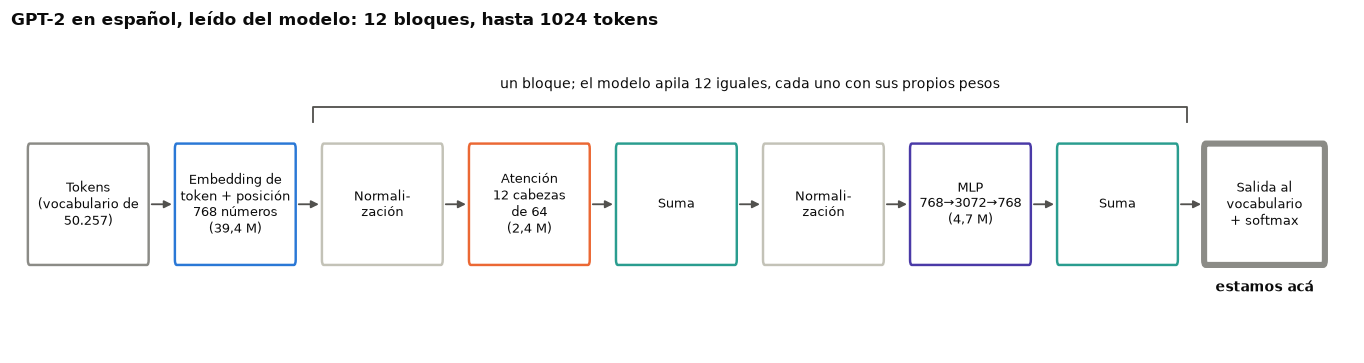

In [17]:
utils.dibujar_mapa_del_modelo(modelo, estamos_aca="salida")

Cada renglón de logits responde «¿qué viene después de este token?», usando solo lo anterior (por la máscara causal). Miramos el renglón de «a»: qué propone el modelo después de *Aquí me pongo a*. Softmax convierte los 50.257 puntajes en probabilidades.

'cantar' queda en el puesto 18, con probabilidad 0.009


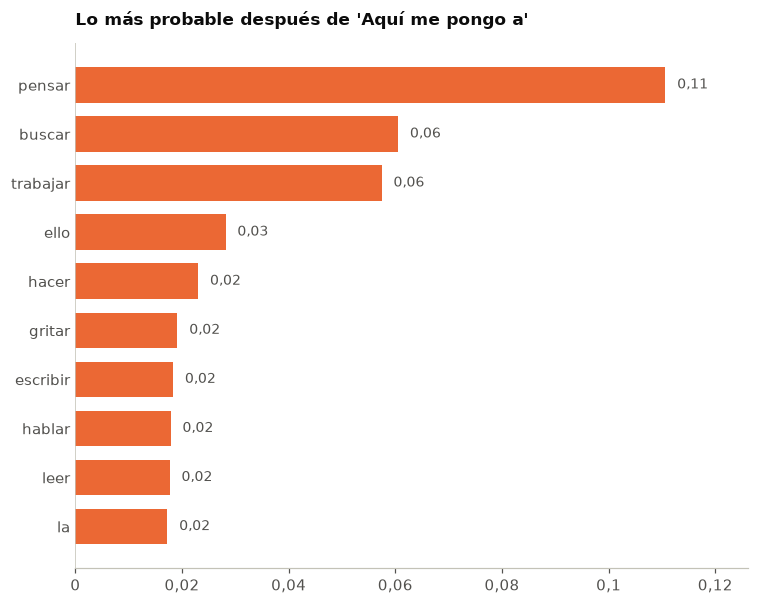

In [18]:
posicion_de_a = 3
probabilidades = utils.softmax(logits[posicion_de_a])
orden = np.argsort(-probabilidades)

propuestas = []
valores = []
for numero in orden[0:10]:
    propuestas.append(tokenizador.decode(int(numero)).strip())
    valores.append(probabilidades[numero])

id_de_cantar = int(ids_del_verso[0, posicion_de_cantar])
lugares_de_cantar = np.where(orden == id_de_cantar)[0]
puesto_de_cantar = int(lugares_de_cantar[0]) + 1
probabilidad_de_cantar = probabilidades[id_de_cantar]
print(f"'cantar' queda en el puesto {puesto_de_cantar}, "
      f"con probabilidad {probabilidad_de_cantar:.3f}")
utils.dibujar_barras(
    nombres=propuestas,
    valores=valores,
    titulo="Lo m\u00e1s probable despu\u00e9s de 'Aqu\u00ed me pongo a'",
    color=utils.NARANJA,
)

> **Para mirar.**
>
> - Propone verbos (*pensar*, *buscar*, *trabajar*): lo que suele venir después de *me pongo a*. Ninguno pasa de 0,12: hay muchas continuaciones posibles.
> - «cantar» está en el puesto 18, con 0,009. Para el modelo, el comienzo del *Martín Fierro* no es la continuación más esperable.

**Python nuevo:** `np.where(orden == id_de_cantar)[0]` dice en qué lugar del orden está «cantar»; se le suma 1 porque los puestos se cuentan desde 1.

## 6. Aciertos y errores a lo largo del verso

Repetimos para cada posición: qué token propone primero el modelo, y en qué puesto quedó el token que de verdad sigue en el verso.

In [19]:
resultados = []
for posicion in range(cantidad_de_tokens - 1):
    probabilidades = utils.softmax(logits[posicion])
    orden = np.argsort(-probabilidades)
    siguiente = int(ids_del_verso[0, posicion + 1])
    lugares = np.where(orden == siguiente)[0]
    puesto = int(lugares[0]) + 1
    resultados.append({
        "despues_de": rotulos[posicion],
        "propone": tokenizador.decode(int(orden[0])).strip(),
        "sigue": rotulos[posicion + 1],
        "puesto": puesto,
    })

for resultado in resultados:
    print(f"despues de {resultado['despues_de']:>7}: propone "
          f"{resultado['propone']:>8}; sigue {resultado['sigue']:>7}, "
          f"en el puesto {resultado['puesto']}")

despues de    Aquí: propone        ,; sigue      me, en el puesto 13
despues de      me: propone       he; sigue   pongo, en el puesto 23
despues de   pongo: propone        a; sigue       a, en el puesto 1
despues de       a: propone   pensar; sigue  cantar, en el puesto 18
despues de  cantar: propone        .; sigue      al, en el puesto 25
despues de      al: propone      son; sigue  compás, en el puesto 3
despues de  compás: propone       de; sigue      de, en el puesto 1
despues de      de: propone       la; sigue      la, en el puesto 1
despues de      la: propone   música; sigue     vig, en el puesto 283
despues de     vig: propone       ía; sigue       ü, en el puesto 138
despues de       ü: propone      ita; sigue     ela, en el puesto 10


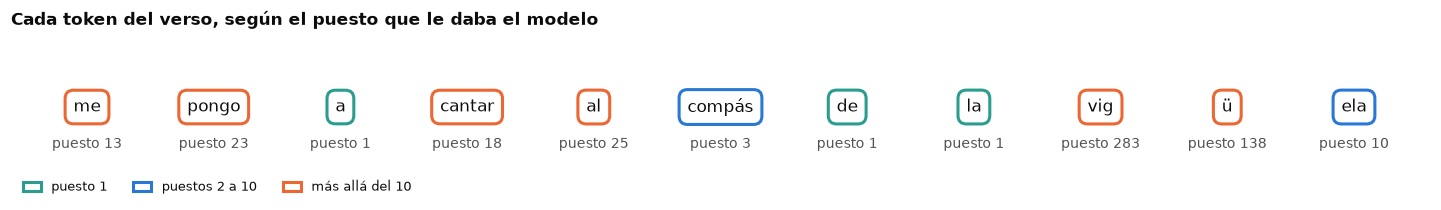

In [20]:
piezas = []
clases = []
notas = []
for resultado in resultados:
    piezas.append(resultado["sigue"])
    notas.append(f"puesto {resultado['puesto']}")
    if resultado["puesto"] == 1:
        clases.append("acierto")
    elif resultado["puesto"] <= 10:
        clases.append("cerca")
    else:
        clases.append("lejos")

utils.dibujar_fichas(
    piezas=piezas,
    clases=clases,
    estilos={
        "acierto": (utils.VERDE_AZULADO, "puesto 1"),
        "cerca": (utils.AZUL, "puestos 2 a 10"),
        "lejos": (utils.NARANJA, "m\u00e1s all\u00e1 del 10"),
    },
    titulo="Cada token del verso, seg\u00fan el puesto que le daba el modelo",
    notas=notas,
)

> **Para mirar.**
>
> - Acierta lo gramatical: «a» después de *pongo*, «de» después de *compás*, «la» después de *de*.
> - «compás» queda tercero después de *al*, detrás de *son* y *piano*: el modelo ya «espera» algo musical.
> - *vigüela* falla del todo (su primera pieza, `vig`, en el puesto 283), aunque después de *la* propone *música*, *canción* y *melodía*. El sentido está cerca; la palabra es rara.

### Microlaboratorio 2 — Lo que propone después de «al compás de la»

**Tarea.** Encontrar el token más probable después de *Aquí me pongo a cantar al compás de la*.
**Producto.** `propuesta`, comprobada contra el modelo.
**Antes de empezar.** Secciones 5 y 6.

Completá las líneas marcadas `COMPLETAR`:

| Línea | Qué tiene que quedar | Con qué |
|---|---|---|
| (1) `logits_de_la` | el renglón de logits de «la» | `logits` en la fila `posicion_de_la` |
| (2) `probabilidades_de_la` | las probabilidades | `utils.softmax` aplicada a `logits_de_la` |
| (3) `numero_mas_probable` | el número del token más probable | `np.argmax` de las probabilidades, convertido con `int` |
| (4) `propuesta` | el token, como texto | `tokenizador.decode` con `numero_mas_probable` |

**Comprobación.** El token de mayor logit según el modelo.

> **Ayuda 1.** Es la celda de la sección 5 con otra posición.
> **Ayuda 2.** `np.argmax` devuelve la posición del valor más grande.

In [21]:
posicion_de_la = 8

logits_de_la = np.zeros(50257)  # COMPLETAR (1)
probabilidades_de_la = np.zeros(50257)  # COMPLETAR (2)
numero_mas_probable = 0  # COMPLETAR (3)
propuesta = ""  # COMPLETAR (4)

print(f"Despues de 'al compas de la' propone: {propuesta!r}")

Despues de 'al compas de la' propone: ''


In [22]:
numero_del_modelo = int(logits_del_modelo[posicion_de_la].argmax())
utils.comprobar(
    propuesta == tokenizador.decode(numero_del_modelo),
    "revisa (1) a (4): no es el token que propone el modelo.",
)

Todavia no. revisa (1) a (4): no es el token que propone el modelo.


## 7. Donde el mecanismo no alcanza: los mismos cálculos, con pesos al azar

Todo lo que hicimos son cuentas: productos, sumas, softmax. ¿Dónde está, entonces, lo que el modelo «sabe»? Para separarlo, armamos **el mismo modelo con pesos al azar**: misma arquitectura, mismas cuentas, sin entrenar. Es un contraste, no un modelo para usar.

`torch.manual_seed` fija el azar: con la misma semilla salen los mismos pesos.

Si todos los tokens tuvieran la misma: 0.20 por cada 10.000


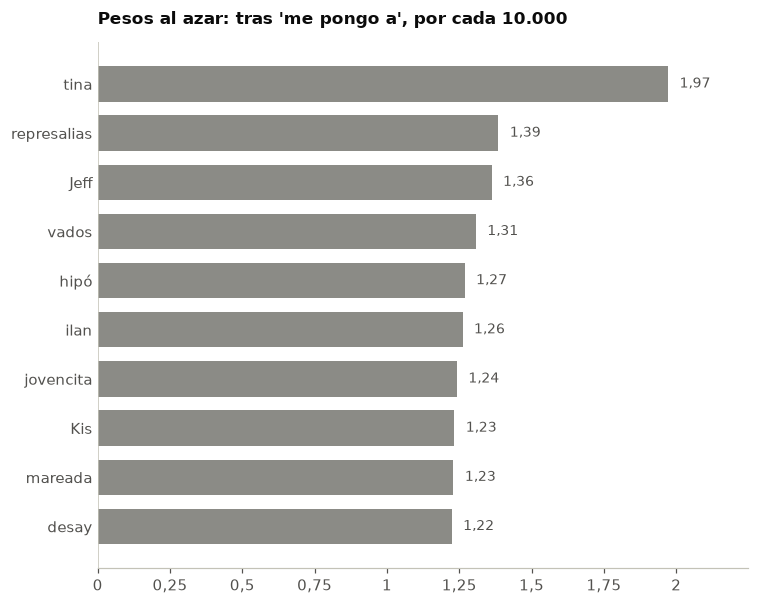

In [23]:
SEMILLA = 24
torch.manual_seed(SEMILLA)
modelo_al_azar = GPT2LMHeadModel(modelo.config)
modelo_al_azar.eval()

with torch.no_grad():
    salida_al_azar = modelo_al_azar(ids_del_verso, output_attentions=True)

logits_al_azar = salida_al_azar.logits[0].numpy()
probabilidades_al_azar = utils.softmax(logits_al_azar[posicion_de_a])
orden_al_azar = np.argsort(-probabilidades_al_azar)

# Las probabilidades son tan chicas que las escribimos por cada 10.000.
propuestas_al_azar = []
valores_al_azar = []
for numero in orden_al_azar[0:10]:
    propuestas_al_azar.append(tokenizador.decode(int(numero)).strip())
    valores_al_azar.append(probabilidades_al_azar[numero] * 10000)

reparto_parejo = 10000 / len(probabilidades_al_azar)
print(f"Si todos los tokens tuvieran la misma: {reparto_parejo:.2f} "
      "por cada 10.000")
utils.dibujar_barras(
    nombres=propuestas_al_azar,
    valores=valores_al_azar,
    titulo="Pesos al azar: tras 'me pongo a', por cada 10.000",
    color=utils.GRIS,
)

> **Para mirar.** Las propuestas no tienen relación con el verso (*tina*, *represalias*, *Jeff*) y la más alta tiene 2 por cada 10.000 (0,0002). Un reparto parejo entre los 50.257 tokens daría 0,2: el modelo al azar reparte casi en partes iguales. El mecanismo es idéntico; lo que cambió son los pesos.

Lo mismo pasa con la atención: la fila de «cantar» en la capa 0, cabeza 0, con los dos juegos de pesos.

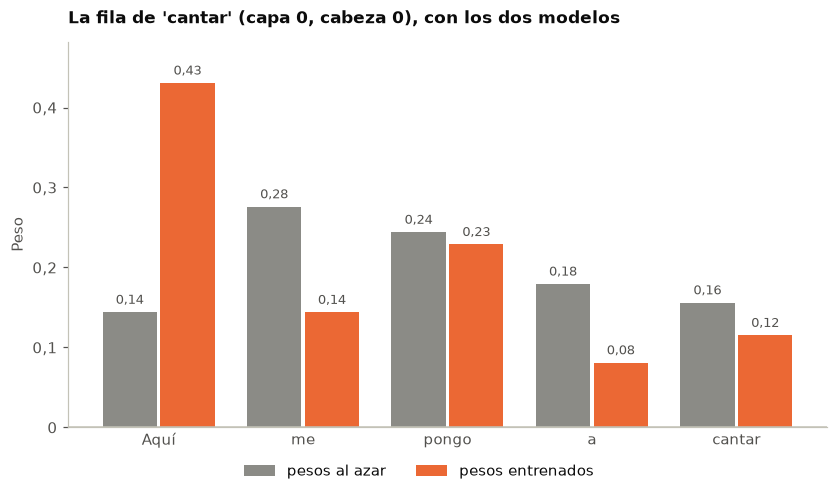

In [24]:
with torch.no_grad():
    salida_entrenada = modelo(ids_del_verso, output_attentions=True)

capa_0_entrenada = salida_entrenada.attentions[0]
capa_0_al_azar = salida_al_azar.attentions[0]
cabezas_entrenadas = capa_0_entrenada[0].numpy()
cabezas_al_azar = capa_0_al_azar[0].numpy()
fila_entrenada = cabezas_entrenadas[0, posicion_de_cantar, 0:5]
fila_al_azar = cabezas_al_azar[0, posicion_de_cantar, 0:5]

utils.dibujar_barras_agrupadas(
    categorias=rotulos[0:5],
    series={
        "pesos al azar": fila_al_azar,
        "pesos entrenados": fila_entrenada,
    },
    titulo="La fila de 'cantar' (capa 0, cabeza 0), con los dos modelos",
    etiqueta_y="Peso",
)

> **Para mirar.** Con pesos al azar, la atención reparte el peso sin un patrón (de 0,14 a 0,28); con los entrenados, se concentra en «Aquí» y «pongo». La máscara causal sigue funcionando en los dos: eso es mecanismo. El patrón es aprendizaje.

**Decisión de uso.** Recalcular el modelo pieza por pieza sirve para saber **qué cuentas hace** y verificar que no hay nada escondido entre la entrada y la distribución final. No sirve para saber **por qué** propone lo que propone: eso está repartido en 124 millones de pesos aprendidos, y ninguna pieza sola lo explica.

## Qué te llevás

- Un bloque de GPT-2 son 12 cabezas de atención mezcladas, una suma residual, una normalización, una red de 3072 neuronas y otra suma; entra y sale una matriz de la misma forma, y por eso se apilan 12.
- Al final, el vector de cada token se compara con cada fila de la tabla de embeddings: un logit por token del vocabulario, y softmax los convierte en la distribución del próximo token. Recalculado a mano, coincide con el modelo.
- El mecanismo no distingue un buen modelo de uno inútil: con pesos al azar, las mismas cuentas proponen *tina* o *represalias*. Lo que el modelo sabe está en los pesos.

**Sigue:** en el cuaderno 04, la atención de BETO, un modelo que mira hacia los dos lados, y qué se puede afirmar a partir de ella. En la unidad 012, cómo se ajustan esos pesos.